# Phase 1: Corpus Setup & Exploratory Data Analysis (CFPB Complaints)

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

ROOT = Path("..").resolve()
df = pd.read_csv(ROOT / "results" / "complaints_clean.csv").dropna(subset=["clean_text", "tokens"])
df["raw_words"] = df["clean_text"].str.split().str.len()
df["clean_tokens"] = df["tokens"].str.split().str.len()
print(f"Valid cleaned complaints: {len(df):,}")
display(df[["raw_words", "clean_tokens"]].describe())

Valid cleaned complaints: 65,634


,raw_words,clean_tokens
count,65634.000000,65634.000000
mean,186.677911,70.632660
std,162.811204,62.143966
min,2.000000,1.000000
25%,70.000000,26.000000
50%,134.000000,50.000000
75%,250.000000,94.000000
max,1283.000000,342.000000


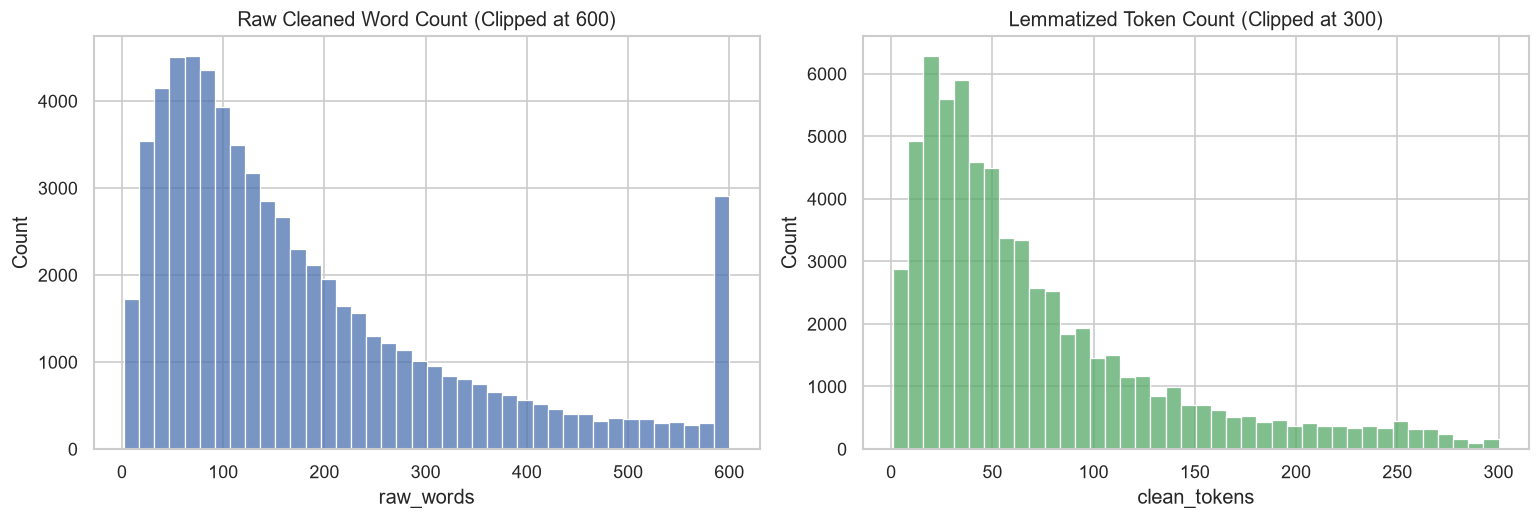

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["raw_words"].clip(upper=600), bins=40, ax=axes[0], color="#4C72B0")
axes[0].set_title("Raw Cleaned Word Count (Clipped at 600)")
sns.histplot(df["clean_tokens"].clip(upper=300), bins=40, ax=axes[1], color="#55A868")
axes[1].set_title("Lemmatized Token Count (Clipped at 300)")
plt.tight_layout()
plt.show()

In [3]:
vec = CountVectorizer(ngram_range=(1, 2), max_features=20)
X = vec.fit_transform(df["tokens"])
ngrams = pd.Series(X.sum(axis=0).A1, index=vec.get_feature_names_out()).sort_values(ascending=False)
display(ngrams.to_frame("frequency"))

,frequency
not,130217
payment,68923
pay,57467
loan,55152
report,51448
call,46910
tell,45214
receive,42751
time,41804
no,40439
